# Experiment 2: Darcy flow

This notebook is one of three experiments comparing **Adam**, **Muon** and **SOAP** as optimizers for the **physics-informed neural operator (PINO)** (Li, Zheng et al., *Physics-Informed Neural Operator for Learning Partial Differential Equations*, arXiv:2111.03794).

The protocol follows the paper's Table 1:
- **Phase 1, operator learning.** Train a Fourier neural operator (FNO) with a data loss on a *coarse* grid plus a PDE-residual loss on a *finer* grid, then measure test error on several grids.
- **Phase 2, instance-wise fine-tuning.** Start from the Adam-trained operator and minimize the PDE loss on one test instance at a time (no data), tracking the error against a reference solution.

For each problem, all three optimizers share the same initialization, data, batches and cosine learning-rate schedule. Learning rates are chosen on a validation set (never the test set).
- **Muon:** orthogonalizes updates of the hidden weight matrices; Adam handles the rest.
- **SOAP:** runs Adam in Shampoo's eigenbasis for every tensor.

Both are implemented in `pino_bench.py`.

**Scale.** These are CPU runs (2 cores) with a half-width FNO (32 channels; the paper uses 64) and fewer iterations than the paper. Absolute errors are therefore above the paper's; the point is the **like-for-like comparison** of the optimizers.

This notebook only *reads* the saved results in `../results/darcy` (set `RUN_EXPERIMENT = True` to regenerate them).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))          # repo root: pino_bench.py, experiments.py, analysis.py
import pandas as pd, matplotlib.pyplot as plt
import analysis as an, experiments as ex
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
PDE = "darcy"


## Problem

Steady Darcy flow $-\nabla\cdot(a\nabla u) = 1$ on $(0,1)^2$ with $u = 0$ on the boundary.

- **Coefficient:** $a = 12$ where a Gaussian random field $\mathcal N(0, (-\Delta + 9I)^{-2})$ is positive and $a = 3$ elsewhere (two media).
- **Reference solutions:** a 5-point flux-conservative finite-difference scheme (harmonic-mean face coefficients) on a 241 × 241 grid; a 481 × 481 run agrees to $5\cdot10^{-4}$.
- **Grids:** data loss on **11 × 11**, PDE loss on **61 × 61**; test on 11, 61 and 121.
- **Boundary condition:** enforced by multiplying the output by $10^{-3}\sin(\pi x)\sin(\pi y)$.
- **PDE residual: a deliberate deviation from the paper.** This uses the *flux-conservative* residual. The paper's nested central-difference residual has an exact least-squares minimizer ~70% away from the true solution (see notebook 04).
- **Splits:** 1000 training, 100 validation and 200 test instances.
- **Model and training:** FNO with width 32 and 12 × 12 modes, 8000 iterations, batch 10 + 10, 2 seeds.

### Configuration
This is the exact configuration used for the saved results (`experiments.cfg_for`).

In [2]:
cfg = ex.cfg_for(PDE)
{k: cfg[k] for k in cfg if k not in ("gen",)}

{'mollifier': 0.001,
 'residual': 'conservative',
 'n_train': 1000,
 'n_val': 100,
 'n_test': 200,
 'model': {'modes': (12, 12),
  'width': 32,
  'layers': 4,
  'pad_frac': 0.25,
  'pad_mode': 'points'},
 'train': {'iters': 8000,
  'bs_data': 10,
  'bs_pde': 10,
  'data_res': 11,
  'pde_res': 61,
  'weights': {'data': 1.0, 'f': 1.0}},
 'test_res': [11, 61, 121],
 'val_res': 61,
 'finetune': {'iters': 1000,
  'n_instances': 5,
  'anchor': 0.0,
  'n_sweep_instances': 3,
  'sweep_frac': 0.5},
 'seeds': [0, 1],
 'sweep': 0.2}

### Reproducing

In [3]:
# Re-running the experiment from scratch takes about 6 hours on 2 CPU cores (resumable; see experiments.py).
# Results are written to ../runs/results; point the analysis cells at it with RESULTS = "../runs/results".
RUN_EXPERIMENT = False
RESULTS = an.RESULTS          # the saved results shipped with the repo
if RUN_EXPERIMENT:
    ex.run(PDE)
    RESULTS = os.path.join(ex.ROOT, "results")

## Learning-rate sweep
Short runs (20% of the full length, seed 0) on the base rates × {1/3, 1, 3}. Whenever the best rate fell on the top edge of the grid, the grid was extended upward (×3) until it didn't. The rate with the lowest **validation** error is used for the full runs.

In [4]:
an.sweep_table(PDE, RESULTS)

,optimizer,lr,iterations,val_error_pct,chosen
0,Adam,0.000333,1600,37.801,
1,Adam,0.001000,1600,28.152,
2,Adam,0.003000,1600,25.423,<- best
3,Adam,0.009000,1600,27.779,
4,Muon,0.000333,1600,40.984,
5,Muon,0.001000,1600,28.476,
6,Muon,0.003000,1600,23.525,
7,Muon,0.009000,1600,23.059,<- best
8,Muon,0.027000,1600,46.079,
9,SOAP,0.001000,1600,30.845,


## Phase 1: operator learning
Final test error (%), mean ± std over seeds, for each test grid.

In [5]:
an.results_table(PDE, RESULTS)

,lr,seeds,test 11,test 61,test 121,time / run (min)
optimizer,,,,,,
Adam,0.003,2,2.61 ± 0.02,8.44 ± 0.26,7.72 ± 0.23,31.8
Muon,0.009,2,2.66 ± 0.02,5.53 ± 0.71,5.16 ± 0.63,30.7
SOAP,0.009,2,2.62 ± 0.06,5.47 ± 0.70,5.02 ± 0.64,35.0


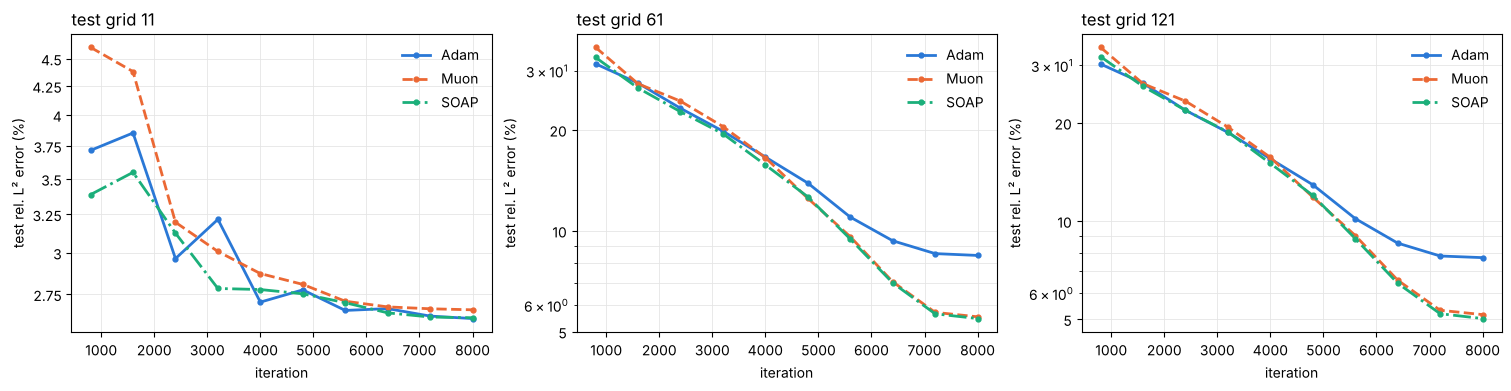

In [6]:
fig = an.plot_phase1(PDE, RESULTS, x='it'); plt.show()

The same curves against wall time:

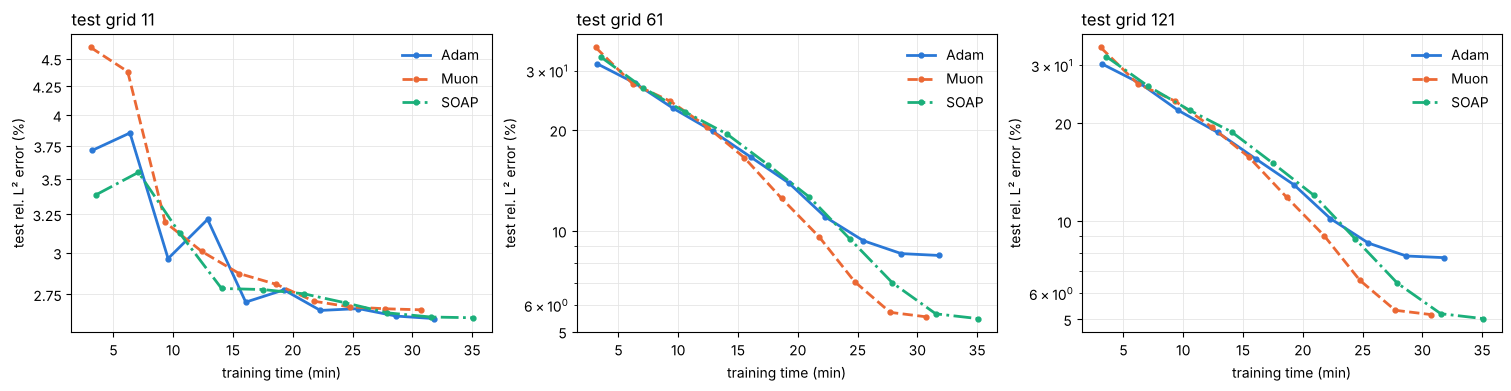

In [7]:
fig = an.plot_phase1(PDE, RESULTS, x='time'); plt.show()

## Phase 2: instance-wise fine-tuning
Each optimizer fine-tunes the **same** Adam-trained operator (seed 0) on each test instance, minimizing only the PDE loss, without the anchor term. The error is measured against the reference solution on the PDE grid.

In [8]:
an.ft_table(PDE, RESULTS)

,lr,instances,steps,start (%),final (%),final per instance (%),time / instance (s)
optimizer,,,,,,,
Adam,0.003,5,1000,2.535,0.119,"[0.106, 0.022, 0.256, 0.022, 0.187]",43
Muon,0.009,5,1000,2.535,0.119,"[0.106, 0.022, 0.256, 0.022, 0.187]",44
SOAP,0.009,5,1000,2.535,0.119,"[0.106, 0.022, 0.256, 0.022, 0.187]",81


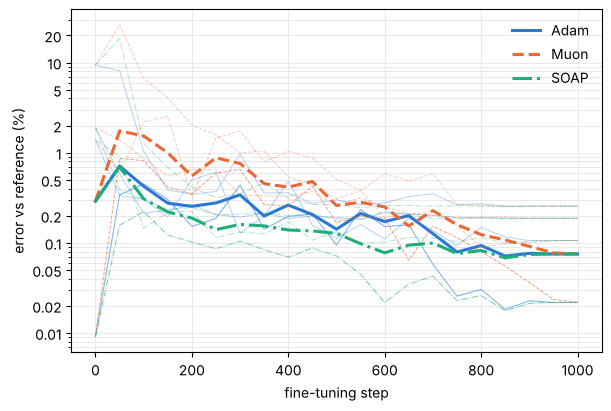

In [9]:
fig = an.plot_phase2(PDE, RESULTS, x='it'); plt.show()

## Observations

- **On the coarse data grid the three optimizers tie** (≈2.6%): they fit the data equally well.
- **On the fine grids, where the PDE loss acts, Muon and SOAP beat Adam by about a third.** On 61 × 61: Adam 8.4%, Muon 5.5%, SOAP 5.5%. Muon and SOAP tie within their seed spread (±0.7).
- **Phase 2: all three reach exactly the same error** (0.12% on average), with identical per-instance values to four digits. Notebook 04 shows this is the error of the *exact minimizer of the discrete PDE loss*: every optimizer reaches the discretization floor, so final accuracy is set by the grid, not the optimizer. Adam is the cheapest way there (43 s per instance against 81 s for SOAP).
- **Paper's PINO with Adam (width 64):** 5.23 / 1.56 / 1.58% on 11 / 61 / 211.